In [187]:
import math
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.metrics import r2_score


import torch
import torch.nn as nn 
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim
from torch.optim import lr_scheduler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [188]:
df = pd.read_csv('../ML-Aided-NR-V2X-QoS-Predictions/dataset.csv')
df = df.drop(columns=['Unnamed: 0']) 
df.head()

,X,Y,throughput,mcs,distance,pktsize,delay,jitter,sinr,power,dlpathloss,pdr
0,146.601387,368.116530,1.743593,13,184.225706,190,3.242855,0.000000,-1.38581,15,-95.2246,99
1,143.260663,365.862937,1.743592,13,188.238131,190,6.579737,1.241554,-3.11075,15,-95.3060,99
2,137.782258,362.167301,1.743593,13,194.819602,190,3.242855,0.000000,-1.24068,15,-95.5003,99
3,131.346059,357.825556,1.743592,13,202.553954,190,6.579767,1.241449,-3.51258,15,-95.8110,99
4,128.942275,355.120683,1.742541,13,206.124022,190,9.782037,1.008803,-3.02864,15,-96.1639,99


[]

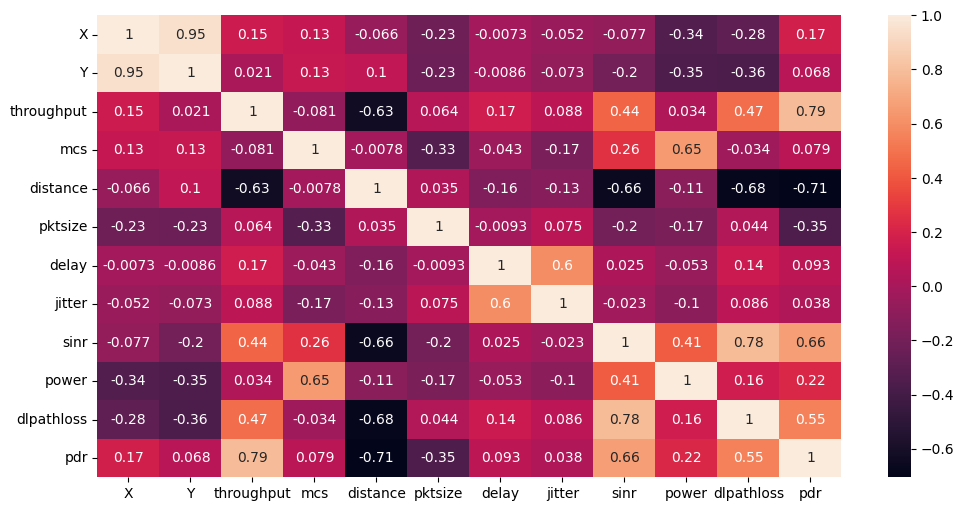

In [189]:
import seaborn as sns

df_clean = df.dropna()
df_clean = df_clean[:1000]
plt.figure(figsize=(12, 6))
sns.heatmap(df_clean.corr(), annot = True)
plt.plot()

In [190]:
df.drop_duplicates(inplace=True)
df.shape

(8720, 12)

In [191]:
print(df.isnull().sum())

X                0
Y                0
throughput       0
mcs              0
distance       103
pktsize          0
delay            0
jitter        3097
sinr             0
power            0
dlpathloss       0
pdr              0
dtype: int64


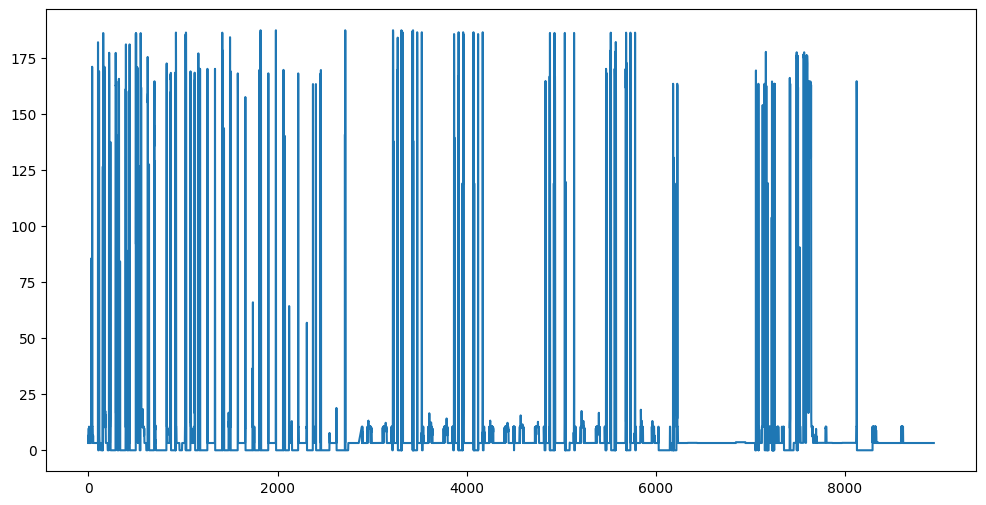

In [192]:
plt.figure(figsize=(12, 6))
plt.plot(df['delay'])
plt.show()

In [193]:
print(df['delay'])

0       3.242855
1       6.579737
2       3.242855
3       6.579767
4       9.782037
          ...   
8936    3.242855
8937    3.242855
8938    3.242855
8939    3.242855
8940    3.242855
Name: delay, Length: 8720, dtype: float64


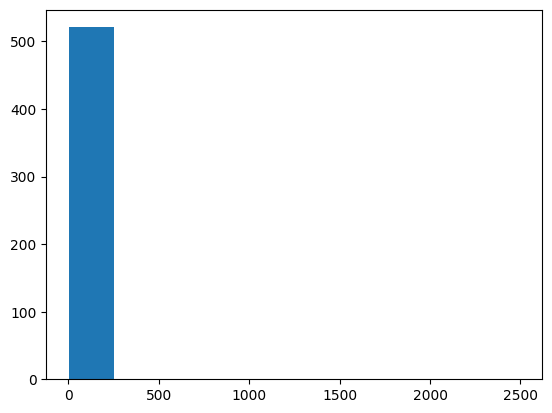

In [194]:
delay_freq = df['delay'].value_counts()
plt.hist(delay_freq)
plt.show()

In [195]:
print(len(df['delay'].unique()))

526


In [196]:
# from pandas.plotting import autocorrelation_plot

# plt.figure(figsize=(10, 4))
# autocorrelation_plot(df['delay'])
# plt.title("Autocorrelation of delay")
# plt.show()

In [197]:
# cols = ['X', 'Y', 'throughput', 'mcs', 'distance', 'pktsize', 'delay', 'jitter', 'pdr']
# cols = ['throughput', 'distance', 'sinr', 'dlpathloss', 'delay']
cols = ['delay', 'jitter']
num_col = len(cols)
data = df[cols]
print(cols)

['delay', 'jitter']


In [198]:
# max_lag = 15

# lags = range(-max_lag, max_lag + 1)
# for feature in cols:
#     if feature == 'delay':
#         continue
#     cross_corrs = [df['delay'].corr(df[feature].shift(lag)) for lag in lags]
#     plt.title(f"Cross correlation Delay vs {feature}")
#     plt.plot(cross_corrs)
#     plt.grid()
#     plt.show()

In [199]:
import pandas as pd

missing_mask = df['jitter'].isna()
missing_groups = (missing_mask != missing_mask.shift()).cumsum()
# print(missing_groups)

nan_ranges = df[missing_mask].groupby(missing_groups).apply(
    lambda g: pd.Series({'Start_Index': g.index[0], 'End_Index': g.index[-1]})
).reset_index(drop=True)

print(nan_ranges)

   Start_Index  End_Index
0         2892       6029


In [200]:
from sklearn.linear_model import LinearRegression

clean = data[['jitter', 'delay']].dropna()

model = LinearRegression()
model.fit(clean[['delay']], clean[['jitter']])

missing_jitter = df['jitter'].isnull()
# print(missing_jitter)
predicted = model.predict(df.loc[missing_jitter, ['delay']])
df.loc[missing_jitter, 'jitter'] = predicted

In [201]:
from sklearn.linear_model import LinearRegression

clean = df[['distance', 'pdr']].dropna()

model = LinearRegression()
model.fit(clean[['pdr']], clean[['distance']])

missing_dist= df['distance'].isnull()
# print(missing_jitter)
predicted = model.predict(df.loc[missing_dist, ['pdr']])
df.loc[missing_dist, 'distance'] = predicted

In [202]:
df.isnull().sum()

X             0
Y             0
throughput    0
mcs           0
distance      0
pktsize       0
delay         0
jitter        0
sinr          0
power         0
dlpathloss    0
pdr           0
dtype: int64

In [203]:
def sliding_window_augmentation(df, cols, L=100, s=10, add_noise=True, noise_level=0.02):
    X = df[cols].values
    T, D = X.shape
    
    n_windows = max(0, (T - L) // s)  
    
    if n_windows <= 0:
        return np.array([]), np.array([])

    windows = np.zeros((n_windows, L, D))
    targets = np.zeros((n_windows, D))
    
    col_stds = df[cols].std().values

    for i in range(n_windows):
        start = i * s
        if start + L >= T:
            break
            
        w = X[start].copy()
        
        target = X[start+L].copy()

        if add_noise:
            noise = np.random.randn(*w.shape) * (col_stds * noise_level)
            w += noise
            target_noise = np.random.randn(*target.shape) * (col_stds * noise_level)
            target += target_noise

        windows[i] = w
        targets[i] = target

    return windows, targets

In [204]:
from torch.utils.data import Dataset

class QoSDataset(Dataset):
    def __init__(self, windowed_data, targets, feature_index):
        self.X = torch.tensor(windowed_data, dtype=torch.float32)
        
        self.y = torch.tensor(
            targets[:, feature_index], 
            dtype=torch.float32
        ).unsqueeze(-1)  

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [205]:
def create_autoregressive_dataset(data, cols, throughput_col_index, window_len=100, stride=10):
    windows, targets = sliding_window_augmentation(
        data, cols, L=window_len, s=stride, add_noise=False
    )
    
    windows_noisy, targets_noisy = sliding_window_augmentation(
        data, cols, L=window_len, s=stride, add_noise=True, noise_level=0.02
    )
    
    if len(windows) > 0 and len(windows_noisy) > 0:
        all_windows = np.concatenate([windows, windows_noisy], axis=0)
        all_targets = np.concatenate([targets, targets_noisy], axis=0)
    elif len(windows) > 0:
        all_windows = windows
        all_targets = targets
    else:
        raise ValueError("No valid windows created")
    
    print(f"Original rows: {len(data)}")
    print(f"Clean windows: {windows.shape[0] if len(windows) > 0 else 0}")
    print(f"Noisy windows: {windows_noisy.shape[0] if len(windows_noisy) > 0 else 0}")
    print(f"Total windows: {all_windows.shape[0]}")
    print(f"Input shape: {all_windows.shape}")
    print(f"Target shape: {all_targets.shape}")
    
    dataset = QoSDataset(all_windows, all_targets, throughput_col_index)
    
    return dataset, all_windows, all_targets

In [206]:
print(cols)

['delay', 'jitter']


In [207]:
delay_feature_index = 6

In [208]:
dataset, windows, targets = create_autoregressive_dataset(
    df, cols, 0, window_len=5, stride=10
)

Original rows: 8720
Clean windows: 871
Noisy windows: 871
Total windows: 1742
Input shape: (1742, 5, 2)
Target shape: (1742, 2)


In [209]:
print(cols)

['delay', 'jitter']


In [210]:
total_len = len(dataset)
train_len = int(0.8 * total_len)
test_len = total_len - train_len

In [211]:
train_dataset, test_dataset = random_split(dataset, [train_len, test_len])

In [212]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [213]:
for X, y in train_loader:
    print(X.shape)
    print(y.shape)
    break

torch.Size([32, 5, 2])
torch.Size([32, 1])


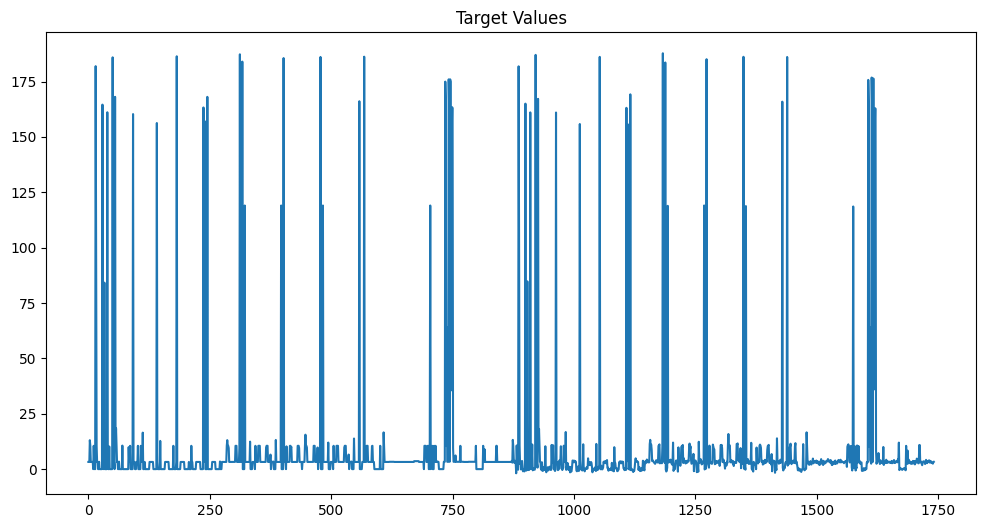

In [214]:
#visualizing the targets
import numpy as np

y_values = torch.stack([dataset[i][1] for i in range(len(dataset))]).numpy().flatten()

plt.figure(figsize=(12, 6))
plt.plot(y_values, label='Target Values')
plt.title('Target Values')
plt.show()

In [215]:
class LSTM(nn.Module):
    def __init__(self, input_size=12, output_size=100, hidden_size=50, num_layers=3, dropout=0.3, bidirectional=False):
        super(LSTM, self).__init__()
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        self.lstm = nn.LSTM(
            input_size, 
            hidden_size, 
            num_layers, 
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional
        )

        direction_factor = 2 if bidirectional else 1
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * direction_factor, 128),
            nn.ReLU(),
            nn.Linear(128, output_size)
        )

    def forward(self, x):
        h0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        out = out[:, -1, :]  # take the last time step
        out = self.fc(out)
        return out

In [216]:
def train(model, trainloader, criterion, optimizer, epoch, scheduler=None):
    model.train()
    epoch_loss = 0

    for X, y in trainloader:
        model.to(DEVICE)
        X, y = X.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        pred = model(X)
        loss = criterion(pred.squeeze(), y.squeeze())
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    if scheduler is not None:
        scheduler.step()
    
    avg_loss = epoch_loss / len(trainloader)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}: Train Loss = {avg_loss:.4f}")
    
    return avg_loss

In [217]:
from sklearn.metrics import r2_score
import torch 

def validate(model, valloader, criterion, epoch):
    model.eval()
    epoch_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X, y in valloader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            pred = model(X)
            
            loss = criterion(pred.squeeze(), y.squeeze())
            epoch_loss += loss.item()
            
            all_preds.extend(pred.squeeze().cpu().numpy())
            all_targets.extend(y.squeeze().cpu().numpy())

    avg_loss = epoch_loss / len(valloader)
    r2 = r2_score(np.array(all_targets), np.array(all_preds))

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}: Val Loss = {avg_loss:.4f}, R² Score = {r2:.4f}")

    return avg_loss, r2

In [218]:
# param_grid = {
#     'learning_rates': [0.00001, 0.0005, 0.001, 0.005, 0.01],
#     'hidden_sizes': [64, 128],
#     'num_layers': [2, 4],
#     'epochs': [5000]
# }

In [221]:
param_grid = {
    'learning_rates': [0.05],
    'hidden_sizes': [64],
    'num_layers': [2],
    'epochs': [1000]
}

In [222]:
import torch
import torch.nn as nn
import torch.optim as optim
import os
import matplotlib.pyplot as plt
import json

os.makedirs("../plots/delay/wins15", exist_ok=True)
os.makedirs("../results", exist_ok=True)

results = []

for lr in param_grid['learning_rates']:
    for hs in param_grid['hidden_sizes']:
        for nl in param_grid['num_layers']:
            for ep in param_grid['epochs']:
                print(f"lr: {lr} | hs: {hs} | nl: {nl}")

                model = LSTM(input_size=len(cols), output_size=1, hidden_size=hs, num_layers=nl)
                criterion = nn.MSELoss()
                optimizer = optim.Adam(model.parameters(), lr=lr)
                train_losses = []
                val_losses = []
                best_r2 = float('-inf')

                for epoch in range(ep):
                    train_loss = train(model, train_loader, criterion, optimizer, epoch)
                    val_loss, r2 = validate(model, test_loader, criterion, epoch)
                    train_losses.append(train_loss)
                    val_losses.append(val_loss)
                    if r2 > best_r2:
                        best_r2 = r2

                fig, ax = plt.subplots(figsize=(12, 5))
                ax.plot(train_losses, label='Train Loss')
                ax.plot(val_losses, label='Val Loss')
                ax.set_title(f"LR={lr}, Hidden={hs}, Layers={nl}, R2={best_r2:.4f}")
                ax.set_xlabel("Epoch")
                ax.set_ylabel("Loss")
                ax.legend()
                filename = f"../plots/delay/wins15st5/lr{lr}_hs{hs}_nl{nl}_r2{best_r2:.4f}.png"
                plt.tight_layout()
                plt.savefig(filename)
                plt.close(fig)

                result = {
                    'lr': lr,
                    'hidden_size': hs,
                    'num_layers': nl,
                    'epochs': ep,
                    'train_losses': train_losses,
                    'val_losses': val_losses,
                    'best_r2': best_r2
                }
                results.append(result)

lr: 0.05 | hs: 64 | nl: 2
Epoch 10: Train Loss = 927.8085
Epoch 10: Val Loss = 784.5309, R² Score = -0.0071
Epoch 20: Train Loss = 883.9390
Epoch 20: Val Loss = 761.8669, R² Score = 0.0225
Epoch 30: Train Loss = 912.0902
Epoch 30: Val Loss = 768.3427, R² Score = 0.0138
Epoch 40: Train Loss = 892.4753
Epoch 40: Val Loss = 767.9716, R² Score = 0.0155
Epoch 50: Train Loss = 889.9357
Epoch 50: Val Loss = 761.9258, R² Score = 0.0227
Epoch 60: Train Loss = 887.6548
Epoch 60: Val Loss = 761.6852, R² Score = 0.0230
Epoch 70: Train Loss = 888.4088
Epoch 70: Val Loss = 761.5364, R² Score = 0.0232
Epoch 80: Train Loss = 888.4529
Epoch 80: Val Loss = 760.4884, R² Score = 0.0247
Epoch 90: Train Loss = 888.9862
Epoch 90: Val Loss = 761.9036, R² Score = 0.0228
Epoch 100: Train Loss = 887.9638
Epoch 100: Val Loss = 761.6624, R² Score = 0.0231
Epoch 110: Train Loss = 887.4180
Epoch 110: Val Loss = 761.6998, R² Score = 0.0230
Epoch 120: Train Loss = 887.5587
Epoch 120: Val Loss = 761.6908, R² Score = 0.

KeyboardInterrupt: 

In [ ]:
def serialize_results(results):
    def make_serializable(d):
        return {
            k: (v.tolist() if hasattr(v, 'tolist') else v)
            for k, v in d.items()
        }
    return [make_serializable(r) for r in results]

# Save JSON at the end
with open("../results/delay-results-wins15-st5.json", "w") as f:
    json.dump(serialize_results(results), f, indent=4)